# Chinook Music Store: SQL Sales Analysis

**Business questions**
1. Which products (songs, artists, genres) sell the most?
2. How much revenue does each country bring in?
3. How do sales change month by month?

**Bonus:** window functions to rank genres, and to find the top artist in each genre.

**Approach:** write SQL queries (saved in the `sql/` folder), run them from Python, check every join, and chart the results.

**Data:** the Chinook sample database (SQLite).

## 1. Setup
Define the database path and a small helper, `run_query`, that runs a SQL query and returns the answer as a table. We only read from the database. We never change it.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
DB_PATH = PROJECT_ROOT / "data" / "raw" / "chinook_sqlite.sqlite"

def run_query(sql):
    """Run one SQL query and return the answer as a table."""
    with sqlite3.connect(DB_PATH) as con:
        return pd.read_sql(sql, con)

# Test: count the customers
run_query("SELECT COUNT(*) AS Customers FROM Customer")

,Customers
0,59


## 2. Data Checks
Before any analysis: count the rows in the main tables, and check that the money from the invoice lines equals the money from the invoices.

In [2]:
tables = ["Customer", "Invoice", "InvoiceLine", "Track", "Album", "Artist", "Genre"]
counts = {t: int(run_query(f"SELECT COUNT(*) AS n FROM {t}").iloc[0, 0]) for t in tables}
print(counts)

{'Customer': 59, 'Invoice': 412, 'InvoiceLine': 2240, 'Track': 3503, 'Album': 347, 'Artist': 275, 'Genre': 25}


In [3]:
money = run_query("""
SELECT (SELECT ROUND(SUM(UnitPrice * Quantity), 2) FROM InvoiceLine) AS LineTotal,
       (SELECT ROUND(SUM(Total), 2) FROM Invoice) AS InvoiceTotal
""")
money

,LineTotal,InvoiceTotal
0,2328.6,2328.6


### Findings from the data checks
- The database has **59 customers, 412 invoices, 2,240 invoice lines, 3,503 tracks, 347 albums, 275 artists and 25 genres**.
- The money from the invoice lines (price x quantity) equals the money from the invoices: both are **2,328.60**. Either one can be used for revenue.
- Every join is on an Id column, and row counts were checked after each join (for example, 2,240 invoice lines still give 2,240 rows after joining tracks). Joining on `UnitPrice` would create a very large, wrong table.

## 3. Top Artists by Revenue
Songs sold only 1 or 2 copies each, so ranking songs means nothing. Artists have many songs, so their ranking is real.
- Chain of joins: invoice line, song, album, artist.
- Revenue = price x quantity, added up for each artist.
- Check: the join chain must keep all 2,240 invoice lines.

In [4]:
chain_rows = run_query("""
SELECT COUNT(*) AS n
FROM InvoiceLine AS il
JOIN Track  AS t  ON il.TrackId  = t.TrackId
JOIN Album  AS al ON t.AlbumId   = al.AlbumId
JOIN Artist AS ar ON al.ArtistId = ar.ArtistId
""").iloc[0, 0]

assert chain_rows == 2240, "The join chain changed the number of rows"
print("Rows after the join chain:", chain_rows)

Rows after the join chain: 2240


In [5]:
top_artists = run_query("""
SELECT ar.Name AS Artist,
       ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS Revenue,
       SUM(il.Quantity) AS UnitsSold
FROM InvoiceLine AS il
JOIN Track  AS t  ON il.TrackId  = t.TrackId
JOIN Album  AS al ON t.AlbumId   = al.AlbumId
JOIN Artist AS ar ON al.ArtistId = ar.ArtistId
GROUP BY ar.ArtistId, ar.Name
ORDER BY Revenue DESC, ar.Name
LIMIT 10
""")

total = run_query("SELECT SUM(Total) AS t FROM Invoice").iloc[0, 0]
print("Top 10 share of all revenue (%):", round(top_artists.Revenue.sum() / total * 100, 1))
top_artists

Top 10 share of all revenue (%): 31.0


,Artist,Revenue,UnitsSold
0,Iron Maiden,138.60,140
1,U2,105.93,107
2,Metallica,90.09,91
3,Led Zeppelin,86.13,87
4,Lost,81.59,41
5,The Office,49.75,25
6,Os Paralamas Do Sucesso,44.55,45
7,Deep Purple,43.56,44
8,Faith No More,41.58,42
9,Eric Clapton,39.60,40


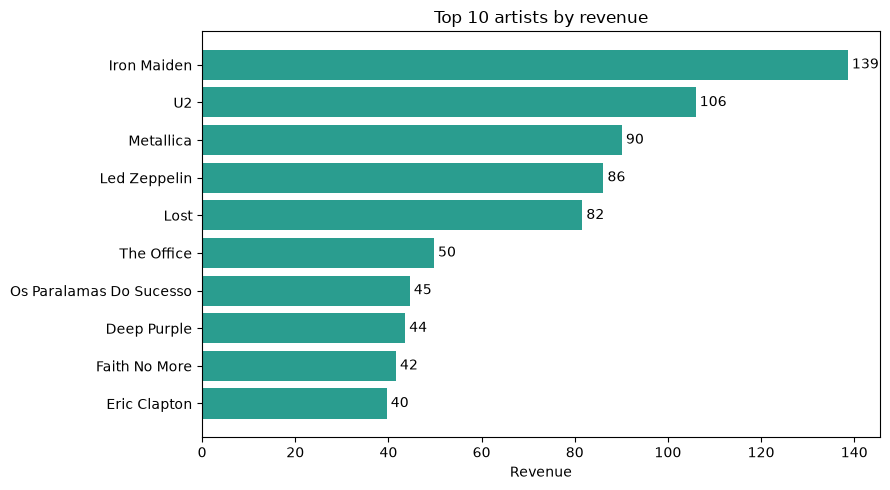

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top_artists.Artist[::-1], top_artists.Revenue[::-1], color="#2a9d8f")
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_title("Top 10 artists by revenue")
ax.set_xlabel("Revenue")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "top_artists.png", dpi=200)
plt.show()

### Findings: top artists
- The join chain keeps all **2,240 invoice lines**, so no revenue is lost or counted twice.
- The **top 10 artists** (out of 275) bring in **31.0%** of all revenue (721.38 of 2,328.60). **Iron Maiden** is first with 138.60 (about 6%), followed by U2, Metallica and Led Zeppelin. Each of these four sold 87 or more copies. The next music artist sold only 45.
- **Lost** and **The Office** are TV shows. They cost 1.99 per episode instead of 0.99, so they rank higher by revenue than by units: Lost is 5th by revenue but 8th by units (41 copies).
- Revenue is price x quantity. A ranking by units would give a slightly different order.

## 4. Revenue by Genre
- Chain of joins: invoice line, song, genre.
- Revenue = price x quantity, added up for each genre. Share = genre revenue / total revenue.
- Check: the genre revenues must add up to the total revenue. If they do, no sale is missing a genre.

In [7]:
genre = run_query("""
SELECT g.Name AS Genre,
       ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS Revenue,
       SUM(il.Quantity) AS UnitsSold
FROM InvoiceLine AS il
JOIN Track AS t ON il.TrackId = t.TrackId
JOIN Genre AS g ON t.GenreId  = g.GenreId
GROUP BY g.GenreId, g.Name
ORDER BY Revenue DESC, g.Name
""")
genre["Share_Percent"] = (genre.Revenue / total * 100).round(1)

assert round(genre.Revenue.sum(), 2) == round(total, 2), "Some revenue is missing from the genre table"

print("Genres that sold:", len(genre))
print("Top 4 share (%):", round(genre.Revenue.head(4).sum() / total * 100, 1))
print("Top 10 share (%):", round(genre.Revenue.head(10).sum() / total * 100, 1))
genre.head(10)

Genres that sold: 24
Top 4 share (%): 73.5
Top 10 share (%): 89.5


,Genre,Revenue,UnitsSold,Share_Percent
0,Rock,826.65,835,35.5
1,Latin,382.14,386,16.4
2,Metal,261.36,264,11.2
3,Alternative & Punk,241.56,244,10.4
4,TV Shows,93.53,47,4.0
5,Jazz,79.20,80,3.4
6,Blues,60.39,61,2.6
7,Drama,57.71,29,2.5
8,Classical,40.59,41,1.7
9,R&B/Soul,40.59,41,1.7


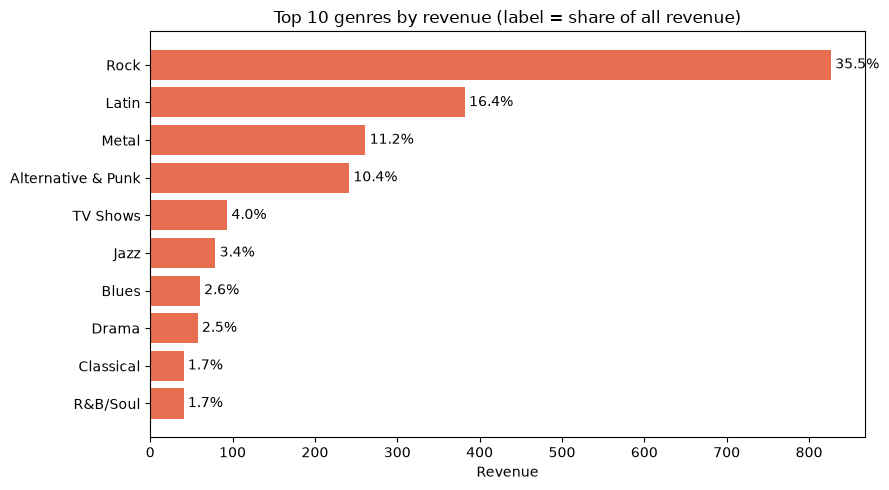

In [8]:
top10 = genre.head(10)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top10.Genre[::-1], top10.Revenue[::-1], color="#e76f51")
ax.bar_label(bars, labels=[f"{s}%" for s in top10.Share_Percent[::-1]], padding=3)
ax.set_title("Top 10 genres by revenue (label = share of all revenue)")
ax.set_xlabel("Revenue")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "top_genres.png", dpi=200)
plt.show()

### Findings: revenue by genre
- The genre revenues add up to the total (**2,328.60**), so every sale has a genre. **24 of the 25 genres** sold at least once.
- **Rock brings 35.5%** of all revenue (826.65), more than twice the next genre, Latin (16.4%). The top 4 genres (Rock, Latin, Metal, Alternative & Punk) bring **73.5%**, and the top 10 bring **89.5%**.
- **TV Shows and Drama** sell few copies (47 and 29) but cost 1.99 per episode, so they rank 5th and 8th by revenue. Together they bring 6.5% of revenue from only 3.4% of units.
- Several genres look alike (Rock and Rock And Roll, Metal and Heavy Metal). They are counted separately, as in the data.

In [9]:
run_query(
"""
SELECT g.Name AS Genre
FROM Genre AS g
LEFT JOIN Track AS t ON g.GenreId = t.GenreId
LEFT JOIN InvoiceLine AS il ON t.TrackId = il.TrackId
GROUP BY g.GenreId, g.Name
HAVING COUNT(il.InvoiceLineId) = 0;
"""
)

,Genre
0,Opera


## 5. Revenue by Country
- Check first: the billing country on each invoice is the same as the customer's country, so we can use `BillingCountry` without a join.
- Revenue from `Invoice.Total`, added up for each country, with customers, invoices, share and revenue per customer.
- Check: the country revenues must add up to the total revenue.

In [10]:
diff = run_query("""
SELECT COUNT(*) AS n
FROM Invoice AS i
JOIN Customer AS c ON i.CustomerId = c.CustomerId
WHERE i.BillingCountry <> c.Country
""").iloc[0, 0]

assert diff == 0, "BillingCountry and Customer.Country are different on some invoices"
print("Invoices with a different country:", diff)

Invoices with a different country: 0


In [11]:
country = run_query("""
SELECT BillingCountry AS Country,
       COUNT(DISTINCT CustomerId) AS Customers,
       COUNT(*) AS Invoices,
       ROUND(SUM(Total), 2) AS Revenue
FROM Invoice
GROUP BY BillingCountry
ORDER BY Revenue DESC, Country
""")
country["Share_Percent"] = (country.Revenue / total * 100).round(1)
country["Revenue_per_Customer"] = (country.Revenue / country.Customers).round(1)

assert round(country.Revenue.sum(), 2) == round(total, 2), "Some revenue is missing from the country table"

print("Countries:", len(country))
print("Top 5 share (%):", round(country.Revenue.head(5).sum() / total * 100, 1))
print("Top 10 share (%):", round(country.Revenue.head(10).sum() / total * 100, 1))
print("Countries with only 1 customer:", (country.Customers == 1).sum())
country.head(10)

Countries: 24
Top 5 share (%): 58.8
Top 10 share (%): 76.1
Countries with only 1 customer: 15


,Country,Customers,Invoices,Revenue,Share_Percent,Revenue_per_Customer
0,USA,13,91,523.06,22.5,40.2
1,Canada,8,56,303.96,13.1,38.0
2,France,5,35,195.10,8.4,39.0
3,Brazil,5,35,190.10,8.2,38.0
4,Germany,4,28,156.48,6.7,39.1
5,United Kingdom,3,21,112.86,4.8,37.6
6,Czech Republic,2,14,90.24,3.9,45.1
7,Portugal,2,14,77.24,3.3,38.6
8,India,2,13,75.26,3.2,37.6
9,Chile,1,7,46.62,2.0,46.6


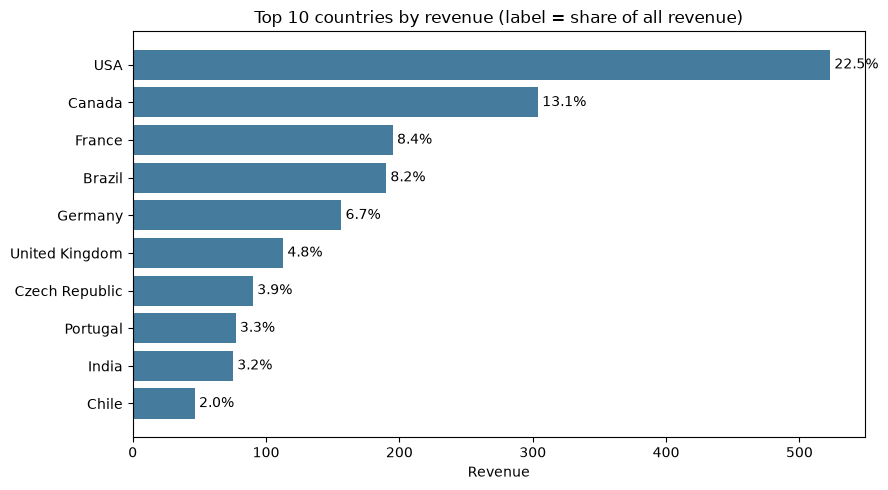

In [12]:
top10c = country.head(10)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top10c.Country[::-1], top10c.Revenue[::-1], color="#457b9d")
ax.bar_label(bars, labels=[f"{s}%" for s in top10c.Share_Percent[::-1]], padding=3)
ax.set_title("Top 10 countries by revenue (label = share of all revenue)")
ax.set_xlabel("Revenue")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "top_countries.png", dpi=200)
plt.show()

### Findings: revenue by country
- `BillingCountry` is the same as the customer's country on all 412 invoices, so no join is needed. The country revenues add up to the total (**2,328.60**).
- Customers come from **24 countries**. The **USA** is first with **523.06 (22.5%)** from 13 customers, then Canada (13.1%), France (8.4%), Brazil (8.2%) and Germany (6.7%). The top 5 countries bring **58.8%** and the top 10 bring **76.1%**.
- **15 of the 24 countries have exactly one customer.**
- Across all 24 countries, revenue per customer ranges only from 37.6 to 46.6. The ranking shows how many customers each country has, not how much each one spends. Czech Republic (45.1) and Chile (46.6) have the highest spend per customer, but each rests on only 1 or 2 customers.
- In the top 10, almost every customer has exactly 7 invoices (India is the exception: 13 invoices for 2 customers). Chinook is a sample database, so patterns like this should not be read as real shopping behavior.

In [13]:
country.Revenue_per_Customer.agg(["min", "max"])

min    37.6
max    46.6
Name: Revenue_per_Customer, dtype: float64

## 6. Sales Over Time
- Date range: the first and last invoice, and the number of months.
- Revenue by month and by year, from `Invoice.Total`. `InvoiceDate` is text, so `strftime` cuts out the year and month.
- Checks: monthly revenue and invoices must add up to the totals (2,328.60 and 412).
- Chart: monthly revenue with a 12-month moving average, to see if there is a trend.

In [14]:
dates = run_query("""
SELECT MIN(InvoiceDate) AS First_Invoice,
       MAX(InvoiceDate) AS Last_Invoice,
       COUNT(DISTINCT strftime('%Y-%m', InvoiceDate)) AS Months
FROM Invoice
""")
dates

,First_Invoice,Last_Invoice,Months
0,2009-01-01 00:00:00,2013-12-22 00:00:00,60


In [15]:
yearly = run_query("""
SELECT strftime('%Y', InvoiceDate) AS Year,
       COUNT(*) AS Invoices,
       ROUND(SUM(Total), 2) AS Revenue
FROM Invoice
GROUP BY Year
ORDER BY Year
""")
yearly

,Year,Invoices,Revenue
0,2009,83,449.46
1,2010,83,481.45
2,2011,83,469.58
3,2012,83,477.53
4,2013,80,450.58


In [16]:
monthly = run_query("""
SELECT strftime('%Y-%m', InvoiceDate) AS Month,
       COUNT(*) AS Invoices,
       ROUND(SUM(Total), 2) AS Revenue
FROM Invoice
GROUP BY Month
ORDER BY Month
""")

assert round(monthly.Revenue.sum(), 2) == round(total, 2), "Monthly revenue does not add up to the total"
assert monthly.Invoices.sum() == 412, "Monthly invoices do not add up to 412"

print("Months:", len(monthly))
print("Months with exactly 37.62:", (monthly.Revenue.round(2) == 37.62).sum())
print("Lowest month:", monthly.loc[monthly.Revenue.idxmin(), "Month"], monthly.Revenue.min())
print("Highest month:", monthly.loc[monthly.Revenue.idxmax(), "Month"], monthly.Revenue.max())

Months: 60
Months with exactly 37.62: 43
Lowest month: 2011-11 23.76
Highest month: 2010-01 52.62


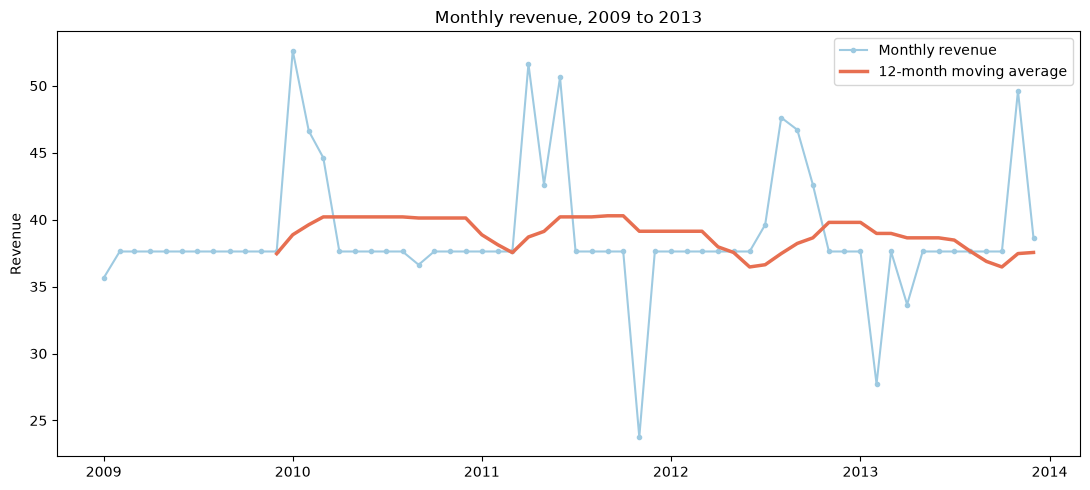

In [17]:
monthly["Date"] = pd.to_datetime(monthly.Month + "-01")
monthly["MA12"] = monthly.Revenue.rolling(12).mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly.Date, monthly.Revenue, color="#9ecae1", marker="o", markersize=3, label="Monthly revenue")
ax.plot(monthly.Date, monthly.MA12, color="#e76f51", linewidth=2.5, label="12-month moving average")
ax.set_title("Monthly revenue, 2009 to 2013")
ax.set_ylabel("Revenue")
ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "monthly_revenue.png", dpi=200)
plt.show()

### Findings: sales over time
- The data covers **60 months**, from 2009-01-01 to 2013-12-22. Monthly revenue and invoices add up to the totals (**2,328.60** and **412**).
- **Sales are flat.** Every year is between **449 and 481**. The best year is 2010 (481.45) and the lowest is 2009 (449.46). The 12-month moving average shows no clear trend.
- **2013 is 5.6% below 2012** (450.58 vs 477.53), but it is not a real drop: it has 80 invoices instead of 83, and the data ends on 22 December.
- **43 of 60 months have exactly 7 invoices and revenue of 37.62.** The highest month is 2010-01 (52.62) and the lowest is 2011-11 (23.76). The high months come in small groups that move from year to year, so there is **no yearly season**.
- Such regular numbers suggest this is a **generated sample database**, so single-month changes should not be read as business signals.

## 7. Bonus: Window Functions
A window function adds a rank column to every row. It does not squash the rows together like `GROUP BY`.
- **Genre ranking** with `ROW_NUMBER`, `RANK` and `DENSE_RANK`, to see how each one treats ties.
- **Top artist in each genre** with `RANK() OVER (PARTITION BY Genre ...)`. `PARTITION BY` restarts the ranking for each genre.
- Checks: SQLite must support window functions (3.25 or higher), and the artist totals from this section must match section 3.

In [18]:
print("SQLite version in Python:", sqlite3.sqlite_version)

SQLite version in Python: 3.50.4


In [19]:
genre_rank = run_query("""
SELECT Genre,
       Revenue,
       ROW_NUMBER() OVER (ORDER BY Revenue DESC, Genre) AS Row_No,
       RANK()       OVER (ORDER BY Revenue DESC)        AS Rank_No,
       DENSE_RANK() OVER (ORDER BY Revenue DESC)        AS Dense_Rank_No
FROM (
    SELECT g.Name AS Genre,
           ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS Revenue
    FROM InvoiceLine AS il
    JOIN Track AS t ON il.TrackId = t.TrackId
    JOIN Genre AS g ON t.GenreId  = g.GenreId
    GROUP BY g.GenreId, g.Name
)
ORDER BY Revenue DESC, Genre
""")

print("Genres ranked:", len(genre_rank))
genre_rank[genre_rank.duplicated("Revenue", keep=False)]

Genres ranked: 24


,Genre,Revenue,Row_No,Rank_No,Dense_Rank_No
8,Classical,40.59,9,9,9
9,R&B/Soul,40.59,10,9,9
20,Electronica/Dance,11.88,21,21,20
21,Heavy Metal,11.88,22,21,20


In [20]:
top_by_genre = run_query("""
SELECT Genre, Artist, Revenue, Rank_In_Genre
FROM (
    SELECT Genre, Artist, Revenue,
           RANK() OVER (PARTITION BY Genre ORDER BY Revenue DESC) AS Rank_In_Genre
    FROM (
        SELECT g.Name AS Genre,
               ar.Name AS Artist,
               ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS Revenue
        FROM InvoiceLine AS il
        JOIN Track  AS t  ON il.TrackId  = t.TrackId
        JOIN Album  AS al ON t.AlbumId   = al.AlbumId
        JOIN Artist AS ar ON al.ArtistId = ar.ArtistId
        JOIN Genre  AS g  ON t.GenreId   = g.GenreId
        GROUP BY g.GenreId, g.Name, ar.ArtistId, ar.Name
    )
)
WHERE Rank_In_Genre = 1
ORDER BY Revenue DESC, Genre, Artist
""")

print("Rows:", len(top_by_genre), "| genres:", top_by_genre.Genre.nunique())

# Check against section 3: U2 and Lost win all of their genres
artist_rev = top_artists.set_index("Artist").Revenue
winner_sum = top_by_genre[top_by_genre.Artist.isin(["U2", "Lost"])].groupby("Artist").Revenue.sum().round(2)
assert winner_sum["U2"] == round(artist_rev["U2"], 2)
assert winner_sum["Lost"] == round(artist_rev["Lost"], 2)
print(winner_sum)

top_by_genre

Rows: 26 | genres: 24
Artist
Lost     81.59
U2      105.93
Name: Revenue, dtype: float64


,Genre,Artist,Revenue,Rank_In_Genre
0,Metal,Metallica,90.09,1
1,Rock,U2,90.09,1
2,TV Shows,Lost,45.77,1
3,Latin,Os Paralamas Do Sucesso,44.55,1
4,Drama,Lost,35.82,1
5,Sci Fi & Fantasy,Battlestar Galactica (Classic),35.82,1
6,Alternative & Punk,Titãs,33.66,1
7,Blues,Eric Clapton,26.73,1
8,Jazz,Spyro Gyra,19.80,1
9,Comedy,The Office,17.91,1


In [21]:
share_in_genre = top_by_genre.merge(genre[["Genre", "Revenue"]], on="Genre", suffixes=("", "_Genre"))
share_in_genre["Share_of_Genre_%"] = (share_in_genre.Revenue / share_in_genre.Revenue_Genre * 100).round(1)
share_in_genre.sort_values("Revenue_Genre", ascending=False).head(6)

,Genre,Artist,Revenue,Rank_In_Genre,Revenue_Genre,Share_of_Genre_%
1,Rock,U2,90.09,1,826.65,10.9
3,Latin,Os Paralamas Do Sucesso,44.55,1,382.14,11.7
0,Metal,Metallica,90.09,1,261.36,34.5
6,Alternative & Punk,Titãs,33.66,1,241.56,13.9
2,TV Shows,Lost,45.77,1,93.53,48.9
8,Jazz,Spyro Gyra,19.80,1,79.20,25.0


### Findings: window functions
- **Ties:** `ROW_NUMBER` gives every row its own number, so it hides ties. `RANK` shows them and then skips a number. `DENSE_RANK` shows them and does not skip. Two pairs of genres are tied: **Classical and R&B/Soul** (40.59, both rank 9, the next genre is rank 11) and **Electronica/Dance and Heavy Metal** (11.88, both rank 21).
- **Top artist in each genre:** 26 rows for 24 genres, because **R&B/Soul** (Amy Winehouse, James Brown) and **World** (João Suplicy, Mônica Marianno) have tied winners. `RANK` is used so ties are shown, not hidden.
- **Metallica** (Metal) and **U2** (Rock) both have 90.09. **Lost** wins both **TV Shows** (45.77) and **Drama** (35.82).
- **The genre belongs to the song, not the artist.** U2 and Lost each appear in two genres. **Iron Maiden**, the top artist overall (138.60), wins only Heavy Metal (11.88), because its money is split across several genres.
- **Check:** the genre-level numbers for U2 (105.93) and Lost (81.59) equal their totals in the artist ranking.
- Some genres depend on one artist: Lost brings **48.9%** of TV Shows and Metallica **34.5%** of Metal, while U2 brings only **10.9%** of Rock.